In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("f1_2026_cleaned.csv")
print(df.head())

   Round      Team           Driver  Points  Wins
0      1   Ferrari  Charles Leclerc    34.0     0
1      1   McLaren     Lando Norris    19.0     0
2      1  Mercedes   George Russell    31.0     1
3      1  Red Bull   Max Verstappen    26.0     0
4      2   McLaren    Oscar Piastri    15.0     0


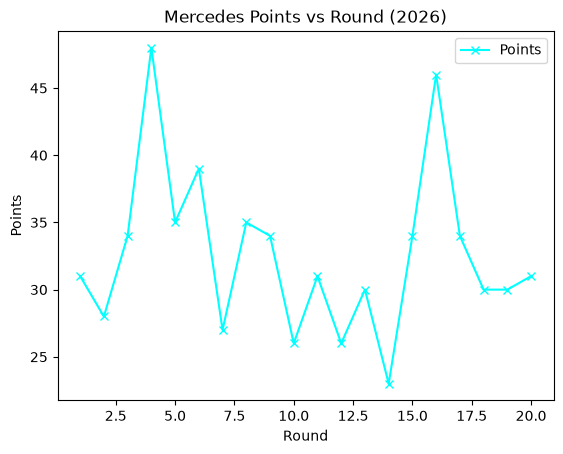

In [9]:
# 1. Line plot: Mercedes Points vs Round
merc = df[df["Team"] == "Mercedes"]
merc.sort_values("Round").plot(x="Round", y="Points", marker="x", color="cyan", title="Mercedes Points vs Round (2026)")
plt.ylabel("Points")
plt.show()

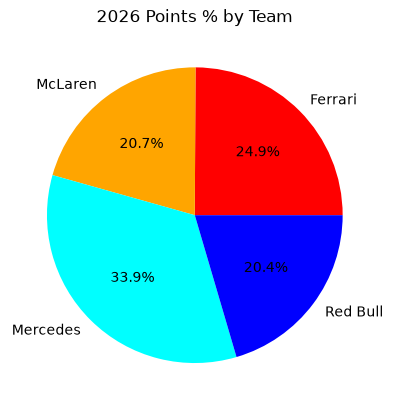

In [5]:
# 2. Pie chart: Points % by Team
team_colors = {"Red Bull": "blue", "Mercedes": "cyan", "Ferrari": "red", "McLaren": "orange"}
team_pts = df.groupby("Team", as_index=False)["Points"].sum()
colors = team_pts["Team"].map(team_colors)
team_pts.set_index("Team").plot.pie(y="Points", autopct="%1.1f%%", title="2026 Points % by Team", legend=False, colors=colors)
plt.ylabel("")
plt.show()

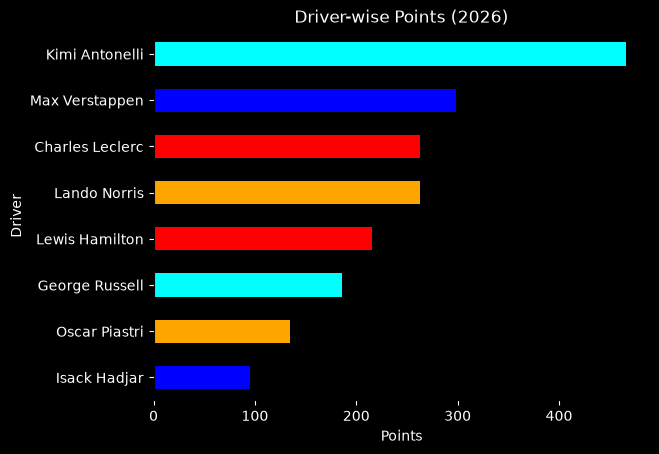

In [6]:
# 3. Horizontal bar: Driver-wise Points
team_colors = {"Red Bull": "blue", "Mercedes": "cyan", "Ferrari": "red", "McLaren": "orange"}
driver_pts = df.groupby(["Driver", "Team"], as_index=False)["Points"].sum().sort_values("Points")
colors = driver_pts["Team"].map(team_colors)
ax = driver_pts.plot(x="Driver", y="Points", kind="barh",
                     title="Driver-wise Points (2026)",
                     legend=False,
                     color=colors)
ax.set_facecolor("black")
ax.figure.set_facecolor("black")
ax.tick_params(colors="white")
ax.xaxis.label.set_color("white")
ax.yaxis.label.set_color("white")
ax.title.set_color("white")
plt.xlabel("Points")
plt.ylabel("Driver")
plt.show()

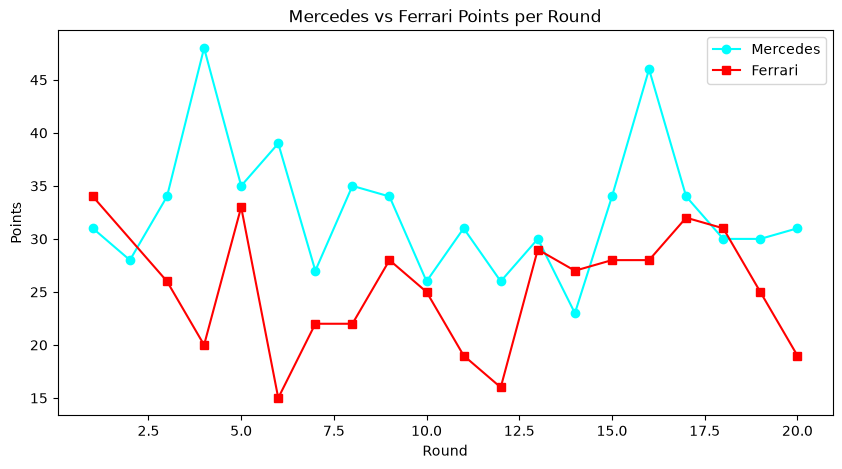

In [7]:
# 4. Multi-line plot: Mercedes vs Ferrari Points per Round
merc = df[df["Team"] == "Mercedes"].sort_values("Round")
ferrari = df[df["Team"] == "Ferrari"].sort_values("Round")

plt.figure(figsize=(10, 5))
plt.plot(merc["Round"], merc["Points"], marker='o', color="cyan", label="Mercedes")
plt.plot(ferrari["Round"], ferrari["Points"], marker='s', color="red", label="Ferrari")
plt.title("Mercedes vs Ferrari Points per Round")
plt.xlabel("Round")
plt.ylabel("Points")
plt.legend()
plt.show()

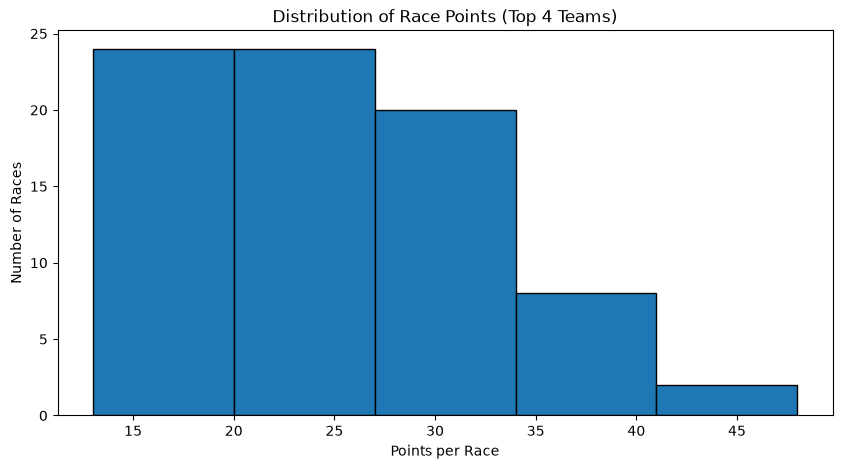

In [8]:
# 5. Histogram: Distribution of Team Points per Race
plt.figure(figsize=(10, 5))
plt.hist(df["Points"], bins=5, edgecolor='black')
plt.title("Distribution of Race Points (Top 4 Teams)")
plt.xlabel("Points per Race")
plt.ylabel("Number of Races")
plt.show()